<a href="https://colab.research.google.com/github/ulloaroman/analisis-pbi-luminosidad/blob/main/notebooks/analisis_luminosidad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#Use mi Drive para subir el archivo que incluye los datos de luminosidad ya que es un archivo muy grande, por lo que voy a hacer un archivo solo con lo que necesito
"""from google.colab import drive
drive.mount('/content/drive')"""

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Importo librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración global de visualización para que los graficos se vean mejor.
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("Entorno inicializado correctamente.")

Entorno inicializado correctamente.


In [16]:
import pandas as pd

#Comienzo a cargar las rutas de los datasets
url_pbi = "https://raw.githubusercontent.com/ulloaroman/analisis-pbi-luminosidad/refs/heads/main/data/raw/gdp_melted.csv"
"""ruta_luces_original = "/content/drive/MyDrive/ntl_adm2_monthly_all.csv" """
url_luces = "https://raw.githubusercontent.com/ulloaroman/analisis-pbi-luminosidad/refs/heads/main/data/raw/luces_por_pais.csv"

#Subo los datasets( utilizo autocompletado de las lineas cuando chequeo que es lo que necesito )
df_pbi = pd.read_csv(url_pbi)
"""df_luces_grande_original = pd.read_csv(ruta_luces)"""
df_luces = pd.read_csv(url_luces)


#Comienzo la exploracion inicial de los datos:

#Visualizo las columnas de los datasets llevando sus respectivos nombres a una lista para poder manipularla
print("Columnas del dataset pbi:", df_pbi.columns.tolist())
print("Columnas del dataset luces:", df_luces.columns.tolist())
"""print("Columnas de luces(original):", df_luces_grande.columns.tolist())"""
#Cruzo las dos tablas por PAIS y por AÑO ( le pedi a Gemini que me recuerde como cruzar dos tablas usando el prompt "Explicame brevemente como utilizar merge para cruzar las dos tablas de datos")
df_final = pd.merge(df_pbi, df_luces, on=['code', 'year'], how='inner')
df_final = df_final.dropna(subset=['gdp', 'luminosity']).reset_index(drop=True)


"""display(df_luces_grande.head(3))"""

#Ahora lo que voy a hacer es achicar el archivo de luminosidad para que quede solo lo que necesito

"""#1- Convierto la columna de fecha a datetime y extraigo el año
df_luces_grande["year"] = pd.to_datetime(df_luces_grande["date"]).dt.year

#2- Agrupo por pais usando el codigo ISO(ISO_A3) y el año, agregando tambien la luminosidad total(ntl_sum)
df_luces_agrupado = df_luces_grande.groupby(["ISO_A3", "year"], as_index=False)["ntl_sum"].sum()

#3- Renombro las columnas para que se adecue perfectamente al archivo del PBI
df_luces_agrupado.rename(columns={"ISO_A3": "code", "ntl_sum": "luminosity"}, inplace=True)

#4- Guardo esta porcion del dataset como csv
df_luces_agrupado.to_csv("luces_por_pais.csv", index=False)

print("¡Archivo reducido con éxito!")
print("Filas del dataset gigante (ADM2):", len(df_luces_grande))#Comparo las filas del dataset original y las del nuevo
print("Filas del dataset agrupado (ADM0):", len(df_luces_agrupado))
display(df_luces_agrupado.head())"""






Columnas del dataset pbi: ['Unnamed: 0', 'country', 'code', 'indicator', 'indicator_code', 'year', 'gdp']
Columnas del dataset luces: ['code', 'year', 'luminosity']

¡Merge exitoso! Tamaño del dataset final: (1588, 8)


,Unnamed: 0,country,code,indicator,indicator_code,year,gdp,luminosity
0,13728,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,2012,2.534637e+09,5.127575e+04
1,13729,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,2012,2.000160e+10,1.429746e+06
2,13730,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,2012,1.280530e+11,2.887530e+06
3,13731,Albania,ALB,GDP (current US$),NY.GDP.MKTP.CD,2012,1.231983e+10,1.067325e+06
4,13732,Andorra,AND,GDP (current US$),NY.GDP.MKTP.CD,2012,3.188809e+09,1.184304e+05


'#1- Convierto la columna de fecha a datetime y extraigo el año\ndf_luces_grande["year"] = pd.to_datetime(df_luces_grande["date"]).dt.year\n\n#2- Agrupo por pais usando el codigo ISO(ISO_A3) y el año, agregando tambien la luminosidad total(ntl_sum)\ndf_luces_agrupado = df_luces_grande.groupby(["ISO_A3", "year"], as_index=False)["ntl_sum"].sum()\n\n#3- Renombro las columnas para que se adecue perfectamente al archivo del PBI\ndf_luces_agrupado.rename(columns={"ISO_A3": "code", "ntl_sum": "luminosity"}, inplace=True)\n\n#4- Guardo esta porcion del dataset como csv \ndf_luces_agrupado.to_csv("luces_por_pais.csv", index=False)\n\nprint("¡Archivo reducido con éxito!")\nprint("Filas del dataset gigante (ADM2):", len(df_luces_grande))#Comparo las filas del dataset original y las del nuevo\nprint("Filas del dataset agrupado (ADM0):", len(df_luces_agrupado))\ndisplay(df_luces_agrupado.head())'

In [29]:
#Luego de la exploracion inicial, agrego lo necesario para cumplir con los requisitos del tp y un extra

print("1- Ultimas 5 filas del dataset consolidado:")
display(df_final.tail())

print("\n2- Tipos de datos por columna:")
print(df_final.dtypes)

print("\n3- Cantidad de valores nulos por columna:")
print(df_final.isnull().sum())

print(f"\n4- Cantidad de filas duplicadas exactas: {df_final.duplicated().sum()}")

print("\n5- Estadisticas descriptivas de las variables numericas:")
display(df_final.describe())

1- Ultimas 5 filas del dataset consolidado:


,Unnamed: 0,country,code,indicator,indicator_code,year,gdp,luminosity
1583,15832,Vanuatu,VUT,GDP (current US$),NY.GDP.MKTP.CD,2019,9.170589e+08,9.720372e+04
1584,15835,Kosovo,XKX,GDP (current US$),NY.GDP.MKTP.CD,2019,7.926108e+09,7.567469e+05
1585,15837,South Africa,ZAF,GDP (current US$),NY.GDP.MKTP.CD,2019,3.514320e+11,1.956632e+07
1586,15838,Zambia,ZMB,GDP (current US$),NY.GDP.MKTP.CD,2019,2.306472e+10,1.363763e+06
1587,15839,Zimbabwe,ZWE,GDP (current US$),NY.GDP.MKTP.CD,2019,2.144076e+10,5.797095e+05



2- Tipos de datos por columna:
Unnamed: 0          int64
country            object
code               object
indicator          object
indicator_code     object
year                int64
gdp               float64
luminosity        float64
dtype: object

3- Cantidad de valores nulos por columna:
Unnamed: 0        0
country           0
code              0
indicator         0
indicator_code    0
year              0
gdp               0
luminosity        0
dtype: int64

4- Cantidad de filas duplicadas exactas: 0

5- Estadisticas descriptivas de las variables numericas:


,Unnamed: 0,year,gdp,luminosity
count,1588.000000,1588.000000,1.588000e+03,1.588000e+03
mean,14758.578086,2015.426322,3.964016e+11,1.594061e+07
std,603.871509,2.269546,1.652452e+12,5.381617e+07
min,13728.000000,2012.000000,3.549207e+07,2.047539e-01
25%,14241.750000,2013.000000,6.583399e+09,2.985198e+05
50%,14757.500000,2015.000000,2.913814e+10,1.548184e+06
75%,15275.750000,2017.000000,1.993922e+11,1.014095e+07
max,15839.000000,2019.000000,2.137440e+13,5.994926e+08


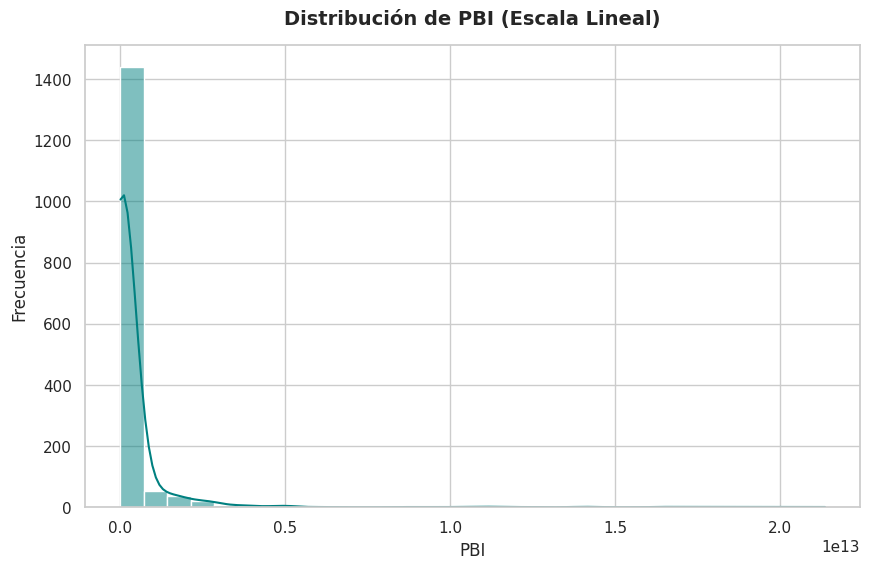

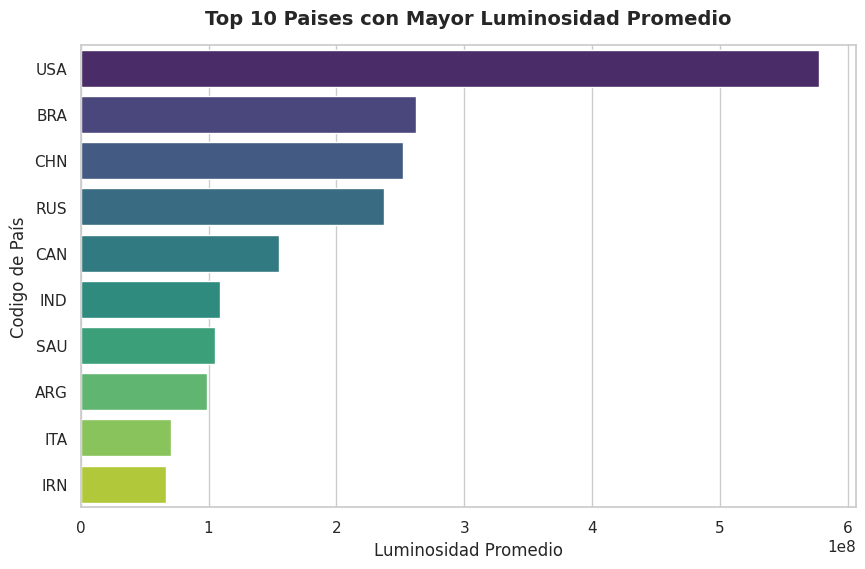

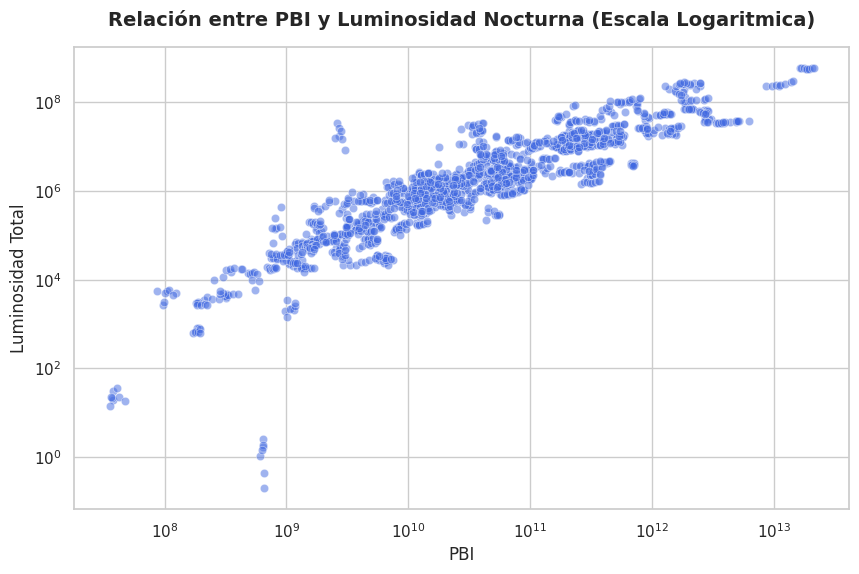

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

#Limpio las columnas "basura"
if "unnamed:0" in df_final.columns:
    df_final = df_final.drop(columns=["unnamed:0"])

#Hago los graficos:

sns.set_theme(style="whitegrid")

#De distribucion ( HISTOGRAMA )
plt.figure(figsize=(10, 6))
sns.histplot(data=df_final, x="gdp", bins=30, kde=True, color="teal")
plt.title("Distribución de PBI (Escala Lineal)", fontsize=14, pad=15)
plt.xlabel("PBI", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)

plt.savefig("grafico_distribucion.png", dpi=300, bbox_inches="tight")
plt.show()

#Grafico de Barras para comparar categorias
top10_luces = df_final.groupby("code")["luminosity"].mean().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_luces, x='luminosity', y='code', hue='code', palette='viridis', legend=False)
plt.title("Top 10 Paises con Mayor Luminosidad Promedio", fontsize=14, pad=15)
plt.xlabel("Luminosidad Promedio", fontsize=12)
plt.ylabel("Codigo de País", fontsize=12)

plt.savefig("grafico_barras.png", dpi=300, bbox_inches="tight")
plt.show()

#Grafico de Dispersion para ver las relaciones entre las variables que estoy estudiando
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x="gdp", y="luminosity",alpha=0.5, color="royalblue")
plt.title("Relación entre PBI y Luminosidad Nocturna (Escala Logaritmica)", fontsize=14, pad=15)
#Escala logaritmica para poder utilizar datos muy "agresivos" y representarlos de mejor manera
plt.xscale("log")
plt.yscale("log")
plt.xlabel("PBI", fontsize=12)
plt.ylabel("Luminosidad Total", fontsize=12)

plt.savefig("grafico_dispersion.png", dpi=300, bbox_inches="tight")
plt.show()



In [30]:
#Le pregunte a Gemini como demostrar que la relacion que veo en el grafico de dispersion se asemeja a algo mas del tipo exponencial

corr_pearson = df_final['gdp'].corr(df_final['luminosity'], method='pearson')
corr_spearman = df_final['gdp'].corr(df_final['luminosity'], method='spearman')

print(f"Coeficiente de correlación de Pearson: {corr_pearson:.3f}")
print(f"Coeficiente de correlación de Spearman: {corr_spearman:.3f}")

Coeficiente de correlación de Pearson: 0.865
Coeficiente de correlación de Spearman: 0.919


# **Interpretacion de los graficos**


1.   **Análisis de la Distribución del PBI:**

      Este histograma nos muestra una distribución completamente asimétrica hacia la derecha (sesgada positivamente) lo que revela que la gran mayoría de los países en la muestra concentran niveles de PBI relativamente bajos a escala global, mientras que un grupo muy reducido funciona como outlier, presentando ingresos masivamente superiores al resto (por eso utilicé la escala logarítmica más adelante).






2.   **Análisis de los Países con Mayor Emisión Lumínica:**

     Este gráfico nos permite identificar la jerarquía de la infraestructura lumínica global. Las naciones que lideran este ranking coinciden con las principales potencias económicas mundiales y con países de gran extensión territorial y alta tasa de urbanización. Este hallazgo refuerza preliminarmente mi intuición principal: la cantidad de luz nocturna emitida por un territorio está completamente relacionada a la magnitud de su actividad económica y desarrollo de infraestructura.




3. **Analisis de la relacion PBI vs LUZ:**  

     Al aplicar una escala logarítmica en ambos ejes, logro estabilizar la varianza observada en el primer gráfico. Podemos ver, a simple vista, una tendencia ascendente, agrupando a la mayoría de las observaciones a lo largo de una trayectoria positiva. Esto demuestra visualmente que, a medida que el PBI de un país se multiplica, su emisión de luz nocturna crece proporcionalmente, lo cual nos indica una elasticidad positiva. La forma compacta y monótona de la nube de puntos es lo que justifica los altos niveles de correlación estadística (Spearman y Pearson) calculados.



# **Conclusion del Analisis de Correlacion**

Los resultados de los coeficientes de correlación de Pearson y de Spearman para líneas rectas y curvas, respectivamente, demuestran una relación positiva muy robusta entre el PBI y la luminosidad nocturna. El hecho de que el coeficiente de Spearman (0,919) sea mayor que el coeficiente de Pearson (0,865) respalda, desde la empiria, el análisis visual hecho antes de realizar el cálculo de los coeficientes. Partí de observar una curva similar a una curva exponencial y finalicé confirmando que la relación entre ambas variables no se puede representar mediante el uso de una línea recta, sino mediante el uso de una curva monótona creciente. Esto confirma mi hipótesis inicial de que la infraestructura lumínica escala exponencialmente con el crecimiento, validando el uso de datos satelitales VIIRS como proxy confiable de la actividad económica.